# ERP Consulting Performance — Analisis Pipeline, Delivery & Support

**Konteks:** PT Beone Optima Solusi (SAP Gold Partner, Tangerang) —
model bisnis konsultan ERP: *lead → opportunity → implementasi → go-live → support*.

> Dataset **100% sintetis** (`src/generate_data.py`, seed=42) — struktur
> dikalibrasi info publik perusahaan; bukan data riil. Lihat `docs/SUMBER_DATA.md`.

**Pertanyaan bisnis:**
1. Sumber lead mana yang paling efektif menghasilkan deal?
2. Produk & industri mana yang menopang revenue?
3. Seberapa sehat delivery: ketepatan go-live & disiplin budget?
4. Apakah support memenuhi SLA, dan kategori apa yang mendominasi?
5. Bisakah keterlambatan proyek diprediksi sejak kickoff?

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi":110,"font.size":10})

leads  = pd.read_csv("../data/raw/leads.csv", parse_dates=[])
opp    = pd.read_csv("../data/raw/opportunities.csv", parse_dates=["tanggal_buat","tanggal_close"])
proyek = pd.read_csv("../data/raw/proyek.csv", parse_dates=["tanggal_mulai","target_golive","tanggal_golive"])
tiket  = pd.read_csv("../data/raw/tiket.csv", parse_dates=["tanggal_dibuat"])
konsultan = pd.read_csv("../data/raw/konsultan.csv")
for n,d in [("leads",leads),("opportunities",opp),("proyek",proyek),("tiket",tiket),("konsultan",konsultan)]:
    print(f"{n:15s} {d.shape}")


leads           (2900, 8)
opportunities   (1221, 9)
proyek          (389, 15)
tiket           (3397, 10)
konsultan       (36, 4)


## 1. Funnel B2B: lead → opportunity → won → proyek

,n,% dari tahap awal
Leads,2900,100.0
Opportunity,1221,42.1
Won,435,15.0
Proyek,389,13.4


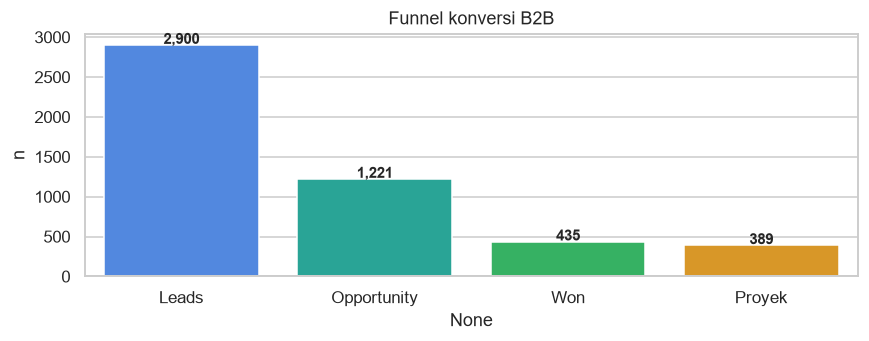

In [2]:
fun = pd.DataFrame({
    "Leads": [len(leads)],
    "Opportunity": [len(opp)],
    "Won": [(opp.hasil=="Won").sum()],
    "Proyek": [len(proyek)]}).T.rename(columns={0:"n"})
fun["% dari tahap awal"] = (100*fun["n"]/fun["n"].iloc[0]).round(1)
display(fun)

fig,ax = plt.subplots(figsize=(8,3.2))
sns.barplot(x=fun.index, y=fun["n"], hue=fun.index, legend=False,
            palette=["#3B82F6","#14B8A6","#22C55E","#F59E0B"], ax=ax)
for i,v in enumerate(fun["n"]): ax.text(i,v+15,f"{v:,}",ha="center",fontweight="bold")
ax.set_title("Funnel konversi B2B"); plt.tight_layout()
plt.savefig("../outputs/figures/funnel_b2b.png"); plt.show()


**Insight:** drop terbesar di lead→opportunity (kualifikasi awal) —
pola khas B2B consulting. Yang lebih menarik: konversi opportunity→won.

,opp,won,win_rate
sumber,,,
Telemarketing,193,33,17.1
LinkedIn,137,40,29.2
Website,244,82,33.6
Partner SAP,159,59,37.1
Event/Workshop,258,98,38.0
Referral Klien,230,123,53.5


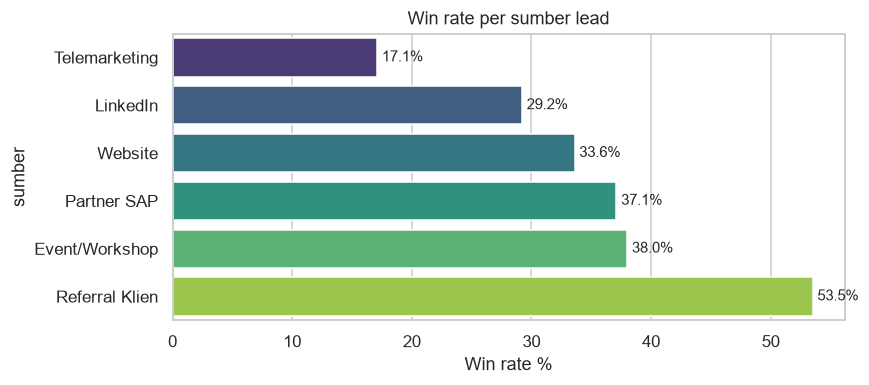

In [3]:
ws = (opp.join(leads.set_index("id_lead")["sumber"], on="id_lead")
      .groupby("sumber").agg(opp=("id_opportunity","count"),
                             won=("hasil",lambda s:(s=="Won").sum()))
      .assign(win_rate=lambda d:(100*d.won/d.opp).round(1))
      .sort_values("win_rate"))
display(ws)
fig,ax = plt.subplots(figsize=(8,3.6))
sns.barplot(x="win_rate",y=ws.index,data=ws,hue=ws.index,legend=False,
            palette="viridis",ax=ax)
ax.set_title("Win rate per sumber lead"); ax.set_xlabel("Win rate %")
for i,v in enumerate(ws.win_rate): ax.text(v+.4,i,f"{v}%",va="center")
plt.tight_layout(); plt.savefig("../outputs/figures/winrate_sumber.png"); plt.show()


**Insight:** referral & event (workshop ala "Business Hacks") menang
telak atas telemarketing — *warm lead* selalu mengalahkan cold outreach.
Implikasi: budget marketing optimal digeser ke event + program referral.

## 2. Produk & industri penopang revenue

,deal,revenue_m,avg_jt,cycle
produk,,,,
Add-on & Integrasi,50,7.17,143.4,58.8
Business Insight,10,0.94,93.8,41.6
SAP Business One,286,99.01,346.2,106.5
SAP S/4HANA GROW,43,36.88,857.6,183.6
TSplus,27,0.88,32.4,20.8
Training/Xpertise Academy,19,0.85,44.9,26.3


C:\Users\PKL01\AppData\Local\Temp\ipykernel_16436\3745015592.py:10: UserWarning: 
The palette list has fewer values (3) than needed (6) and will cycle, which may produce an uninterpretable plot.
  sns.barplot(x=rev.index,y="revenue_m",data=rev,hue=rev.index,legend=False,


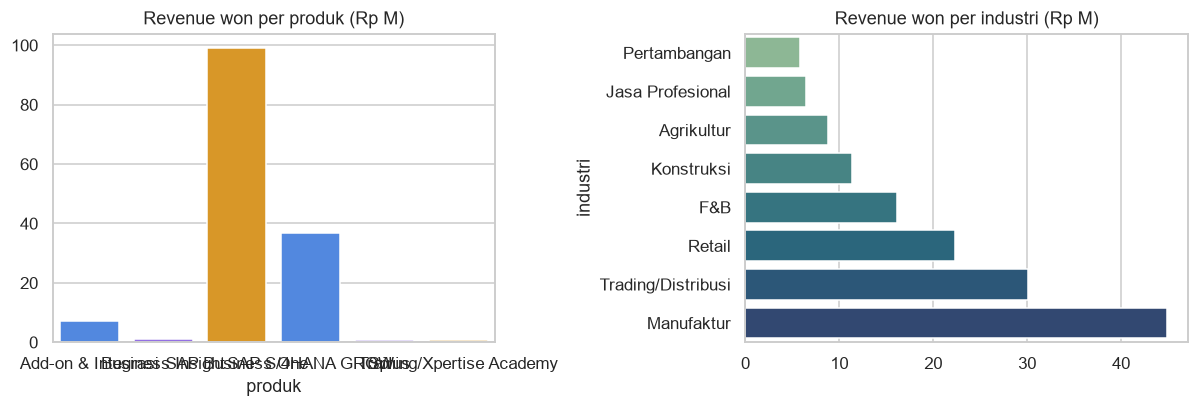

In [4]:
rev = (opp[opp.hasil=="Won"].join(leads.set_index("id_lead")[["tahun","industri"]],on="id_lead")
       .groupby("produk").agg(deal=("id_opportunity","count"),
                              revenue_jt=("nilai_deal_jt","sum"),
                              avg_jt=("nilai_deal_jt","mean"),
                              cycle=("sales_cycle_hari","mean")).round(1))
rev["revenue_m"]= (rev.revenue_jt/1000).round(2)
display(rev[["deal","revenue_m","avg_jt","cycle"]])

fig,axes = plt.subplots(1,2,figsize=(11,3.8))
sns.barplot(x=rev.index,y="revenue_m",data=rev,hue=rev.index,legend=False,
            palette=["#3B82F6","#8B5CF6","#F59E0B"],ax=axes[0])
axes[0].set_title("Revenue won per produk (Rp M)"); axes[0].set_ylabel("")
top_ind=(opp[opp.hasil=="Won"].join(leads.set_index("id_lead")["industri"],on="id_lead")
         .groupby("industri")["nilai_deal_jt"].sum().sort_values()/1000)
sns.barplot(x=top_ind.values,y=top_ind.index,hue=top_ind.index,legend=False,
            palette="crest",ax=axes[1])
axes[1].set_title("Revenue won per industri (Rp M)"); axes[1].set_xlabel("")
plt.tight_layout(); plt.savefig("../outputs/figures/revenue_produk_industri.png"); plt.show()


**Insight:** SAP Business One = mesin volume (pasar UKM); S/4HANA GROW
deal lebih besar + cycle lebih panjang → bauran naik kelas ke mid-market.
Manufaktur & distribusi menopang demand — sesuai positioning riil BeOne.

## 3. Kesehatan delivery: ketepatan go-live & budget

,proyek,on_time_pct,avg_delay,dev_pct
produk,,,,
Add-on & Integrasi,43,53.5,5.7,2.6
Business Insight,8,62.5,0.6,-0.8
SAP Business One,223,57.8,9.9,1.9
SAP S/4HANA GROW,26,50.0,27.6,3.5
TSplus,21,85.7,-1.4,0.7
Training/Xpertise Academy,16,87.5,-0.8,4.1


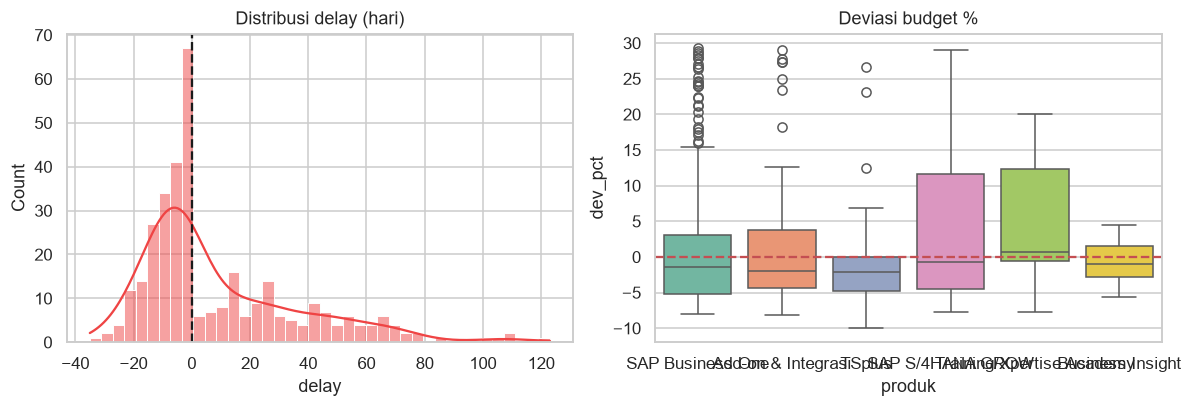

In [5]:
done = proyek.dropna(subset=["tanggal_golive"]).copy()
done["delay"] = done.durasi_aktual_hari - done.durasi_target_hari
done["dev_pct"] = 100*(done.aktual_jt-done.budget_jt)/done.budget_jt

ring = (done.groupby("produk")
        .agg(proyek=("id_proyek","count"),
             on_time_pct=("status_proyek",lambda s:round(100*(s=="Go-live Tepat Waktu").mean(),1)),
             avg_delay=("delay","mean"),
             dev_pct=("dev_pct","mean")).round(1))
display(ring)

fig,axes = plt.subplots(1,2,figsize=(11,3.8))
sns.histplot(done.delay,bins=40,kde=True,color="#EF4444",ax=axes[0])
axes[0].axvline(0,ls="--",color="k"); axes[0].set_title("Distribusi delay (hari)")
sns.boxplot(x="produk",y="dev_pct",data=done,hue="produk",legend=False,
            palette="Set2",ax=axes[1])
axes[1].axhline(0,ls="--",color="r"); axes[1].set_title("Deviasi budget %")
plt.tight_layout(); plt.savefig("../outputs/figures/delivery_delay_budget.png"); plt.show()


**Insight:** S/4HANA punya ekor delay lebih panjang — kompleksitas
proyek enterprise. Overrun terkonsentrasi di modul integrasi — faktor
eksternal (sistem pihak ketiga) lebih sulit dikendalikan daripada coding.

## 4. Support & SLA

,n,avg_jam,sla_pct
prioritas,,,
Critical,258,4.6,89.9
High,925,12.8,89.9
Medium,1361,26.6,87.8
Low,853,54.0,87.7


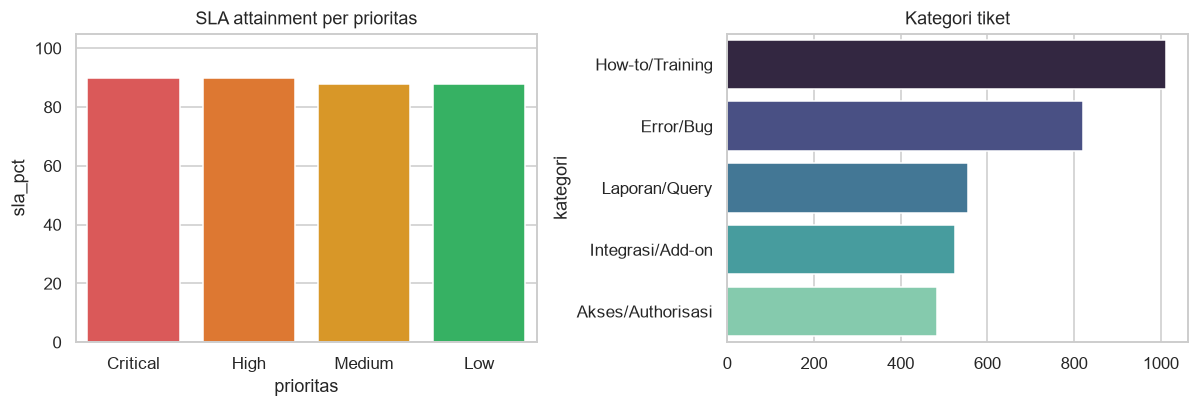

In [6]:
sla = (tiket.groupby("prioritas")
       .agg(n=("id_tiket","count"), avg_jam=("jam_resolusi","mean"),
            sla_pct=("sla_tercapai",lambda s:round(100*s.mean(),1)))
       .reindex(["Critical","High","Medium","Low"]))
display(sla.round(1))

fig,axes = plt.subplots(1,2,figsize=(11,3.8))
sns.barplot(x=sla.index,y="sla_pct",data=sla,hue=sla.index,legend=False,
            palette=["#EF4444","#F97316","#F59E0B","#22C55E"],ax=axes[0])
axes[0].set_title("SLA attainment per prioritas"); axes[0].set_ylim(0,105)
kat = tiket.kategori.value_counts()
sns.barplot(x=kat.values,y=kat.index,hue=kat.index,legend=False,
            palette="mako",ax=axes[1])
axes[1].set_title("Kategori tiket")
plt.tight_layout(); plt.savefig("../outputs/figures/support_sla.png"); plt.show()


**Insight:** dominasi tiket *How-to/Training* = sinyal handover
kurang matang → peluang paket training sebagai recurring revenue.
Critical attainment harus tertinggi — triase bekerja.

## 5. Prediktor keterlambatan (Random Forest, fitur saat kickoff)

ROC-AUC 5-fold CV: 0.625 +- 0.063  (base rate telat=40.1%)


              precision    recall  f1-score   support

           0       0.74      0.45      0.56       202
           1       0.48      0.77      0.59       135

    accuracy                           0.58       337
   macro avg       0.61      0.61      0.57       337
weighted avg       0.64      0.58      0.57       337



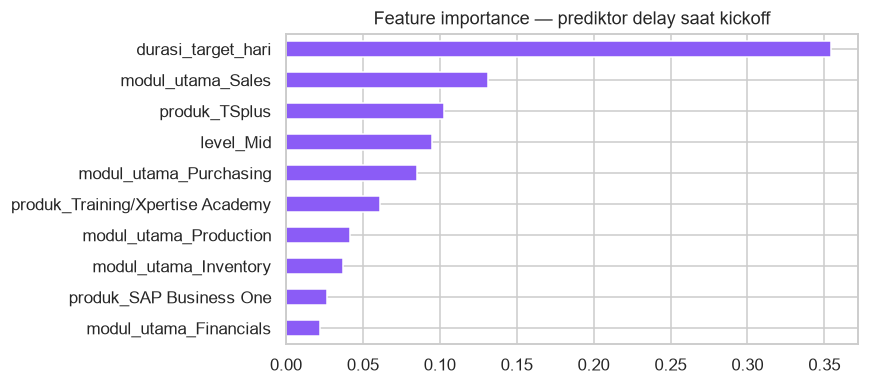

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.metrics import classification_report

d = done.merge(konsultan[["id_konsultan","level"]],on="id_konsultan")
d["late"] = (d.status_proyek=="Go-live Terlambat").astype(int)
X = pd.get_dummies(d[["produk","modul_utama","durasi_target_hari","level"]],
                   drop_first=True).astype(float)
y = d.late
# n proyek selesai kecil (~340) -> 1 split train/test tidak stabil; pakai 5-fold CV
rf = RandomForestClassifier(n_estimators=300,max_depth=3,min_samples_leaf=10,
                            random_state=7,n_jobs=-1)
cv = StratifiedKFold(5,shuffle=True,random_state=7)
aucs = cross_val_score(rf,X,y,cv=cv,scoring="roc_auc")
print(f"ROC-AUC 5-fold CV: {aucs.mean():.3f} +- {aucs.std():.3f}  (base rate telat={y.mean():.1%})")
oof = cross_val_predict(rf,X,y,cv=cv,method="predict_proba")[:,1]
print(classification_report(y,(oof>=.4).astype(int),digits=2))
rf.fit(X,y)

imp = pd.Series(rf.feature_importances_,index=X.columns).nlargest(10).sort_values()
fig,ax=plt.subplots(figsize=(8,3.6))
imp.plot.barh(ax=ax,color="#8B5CF6")
ax.set_title("Feature importance — prediktor delay saat kickoff")
plt.tight_layout(); plt.savefig("../outputs/figures/delay_predictor.png"); plt.show()


## Ringkasan & rekomendasi

1. **Marketing:** alihkan budget dari cold outreach ke referral program +
   event workshop — win rate Referral/Event ±2,2–3,1× telemarketing.
2. **Delivery:** model delay hanya **moderat** (AUC CV ≈ 0,6) — pakai untuk
   *triase* saat kickoff (produk, modul, durasi target, level PIC), bukan
   keputusan tunggal; pasang milestone gate untuk data readiness klien.
3. **Support:** tiket how-to dominan → bundel training pasca go-live +
   knowledge base; menekan volume sekaligus recurring revenue.
4. **Portofolio:** pertahankan volume SAP B1 untuk cash flow; tumbuhkan
   S/4HANA GROW secara selektif (deal besar tapi cycle & risiko delay
   lebih tinggi).

*— [Nama Kamu], Data Analyst project (sintetis, konteks publik)*